In [614]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
plt.rcParams['axes.grid'] = True

In [615]:
r_tube = 3.34e-3 / 2
r_tube_err = 0.5e-3

L_tube = 640.0e-3
L_tube_err = 10e-3

stopper_depth = 11.94e-3
stopper_depth_err = 1.00e-3

h_can = 111.26e-3
h_can_err = 1.00e-3

r_can = 46.28e-3 / 2
r_can_err = 1.00e-3

r_chamber = 36.30e-3 / 2
r_chamber_err = 1.00e-3

chamberless_volume = np.pi * (r_tube**2 * L_tube + (h_can - stopper_depth) * r_can**2)

chamberless_volume_err_1 = np.pi * np.sqrt((2*r_tube*L_tube * r_tube_err)**2 + (r_tube**2 * L_tube_err)**2)
chamberless_volume_err_2 = np.pi * np.sqrt((2*r_can*(h_can - stopper_depth)*r_can_err)**2 + (r_can**2 * h_can_err)**2 + (r_can**2 * stopper_depth_err)**2)

chamberless_volume_err = np.sqrt(chamberless_volume_err_1**2 + chamberless_volume_err_2**2)


g = 9.80

atm = 101325 # 1 atm in pascals

k_B = 1.380649e-23

N_A = 6.0221408e23

R = k_B*N_A



In [616]:

cold_temps_100g = 273.15 + np.array([16.675, 18.037, 18.894, 19.575, 20.871])
cold_temps_100g_err = np.array([0.019, 0.038, 0.038, 0.047, 0.063])

cold_heights_100g = np.array([22.8, 18.2, 13.8, 10.8, 8.4]) * 1e-3
cold_heights_100g_err = np.ones(len(cold_heights_100g)) * 0.5e-3

cold_heights_mass_100g = np.array([21.5, 16.1, 12.1, 9.1]) * 1e-3
cold_heights_mass_100g_err = np.ones(len(cold_heights_mass_100g)) * 0.5e-3

hot_temps_100g = 273.15 + np.array([46.043, 44.254, 41.731, 40.768])
hot_temps_100g_err = np.array([0.017, 0.014, 0.127, 0.013])

hot_heights_mass_100g = np.array([35.2, 28.3, 22.9, 18.5]) * 1e-3
hot_heights_mass_100g_err = np.ones(len(hot_heights_mass_100g)) * 0.5 * 1e-3

hot_heights_100g = np.array([34.5, 29.0, 24.0, 20.1]) * 1e-3 - 1e-3
hot_heights_100g_err = np.ones(len(hot_heights_100g)) * 0.5 * 1e-3

In [617]:

cold_temps_50g = 273.15 + np.array([1.022, 1.599, 1.612, 1.917, 1.837])
cold_temps_50g_err = np.array([0.091, 0.018, 0.037, 0.019, 0.035])


cold_heights_50g = np.array([12.1, 12.0, 8.2, 6.1, 4.0]) * 1e-3
cold_heights_50g_err = np.ones(len(cold_heights_50g)) * 0.5e-3

cold_heights_mass_50g = np.array([11.0, 10.9, 6.8, 4.0]) * 1e-3
cold_heights_mass_50g_err = np.ones(len(cold_heights_mass_50g)) * 0.5e-3

hot_temps_50g = 273.15 + np.array([47.710, 47.668, 47.647, 47.316])
hot_temps_50g_err = np.array([0.082, 0.045, 0.019, 0.057])

hot_heights_mass_50g = np.array([43.0, 38.1, 34.5, 31.1]) * 1e-3
hot_heights_mass_50g_err = np.ones(len(hot_heights_mass_50g)) * 0.5 * 1e-3
hot_heights_50g = np.array([44.3, 38.9, 35.7, 32.0]) * 1e-3
hot_heights_50g_err = np.ones(len(hot_heights_50g)) * 0.5 * 1e-3


In [618]:

cold_temps_20g = 273.15 + np.array([1.978, 1.782, 1.600, 1.830, 2.006])
cold_temps_20g_err = np.array([0.028, 0.029, 0.012, 0.046, 0.055])

cold_heights_20g = np.array([28.1, 25.8, 22.9, 20.5, 18.2]) * 1e-3
cold_heights_20g_err = np.ones(len(cold_heights_20g)) * 0.5e-3

cold_heights_mass_20g = np.array([27.9, 24.8, 22.0, 19.7]) * 1e-3
cold_heights_mass_20g_err = np.ones(len(cold_heights_mass_20g)) * 0.5e-3

hot_temps_20g = 273.15 + np.array([47.590, 47.369, 47.626, 47.144])
hot_temps_20g_err = np.array([0.098, 0.013, 0.120,0.193])

hot_heights_mass_20g = np.array([55.0, 52.7, 50.0, 47.8]) * 1e-3
hot_heights_mass_20g_err = np.ones(len(hot_heights_mass_20g)) * 0.5 * 1e-3
hot_heights_20g = np.array([55.9, 53.0, 50.5, 48.2]) * 1e-3
hot_heights_20g_err = np.ones(len(hot_heights_20g)) * 0.5 * 1e-3

In [619]:
masses = np.array([100e-3, 50e-3, 20e-3])
masses_err = np.ones(3) * 1e-3

cold_temps = np.array([cold_temps_100g, cold_temps_50g, cold_temps_20g])
cold_temps_err = np.array([cold_temps_100g_err, cold_temps_50g_err, cold_temps_20g_err])

cold_heights = np.array([cold_heights_100g, cold_heights_50g, cold_heights_20g])
cold_heights_err = np.array([cold_heights_100g_err, cold_heights_50g_err, cold_heights_20g_err])

cold_heights_mass = np.array([cold_heights_mass_100g, cold_heights_mass_50g, cold_heights_mass_20g])
cold_heights_mass_err = np.array([cold_heights_mass_100g_err, cold_heights_mass_50g_err, cold_heights_mass_20g_err])

hot_temps = np.array([hot_temps_100g, hot_temps_50g, hot_temps_20g])
hot_temps_err = np.array([hot_temps_100g_err, hot_temps_50g_err, hot_temps_20g_err])

hot_heights_mass = np.array([hot_heights_mass_100g, hot_heights_mass_50g, hot_heights_mass_20g])
hot_heights_mass_err = np.array([hot_heights_mass_100g_err, hot_heights_mass_50g_err, hot_heights_mass_20g_err])

hot_heights = np.array([hot_heights_100g, hot_heights_50g, hot_heights_20g])
hot_heights_err = np.array([hot_heights_100g_err, hot_heights_50g_err, hot_heights_20g_err])


cold_volumes = chamberless_volume + np.pi * r_chamber**2 * cold_heights
cold_volumes_err = np.sqrt(chamberless_volume_err**2 + (2*np.pi*r_chamber * cold_heights * r_chamber_err)**2 + (np.pi * r_chamber**2 * cold_heights_err)**2)

cold_volumes_mass = chamberless_volume + np.pi * r_chamber**2 * cold_heights_mass
cold_volumes_mass_err = np.sqrt(chamberless_volume_err**2 + (2*np.pi*r_chamber * cold_heights_mass * r_chamber_err)**2 + (np.pi * r_chamber**2 * cold_heights_mass_err)**2)

hot_volumes = chamberless_volume + np.pi * r_chamber**2 * hot_heights
hot_volumes_err = np.sqrt(chamberless_volume_err**2 + (2*np.pi*r_chamber * hot_heights * r_chamber_err)**2 + (np.pi * r_chamber**2 * hot_heights_err)**2)

hot_volumes_mass = chamberless_volume + np.pi * r_chamber**2 * hot_heights_mass
hot_volumes_mass_err = np.sqrt(chamberless_volume_err**2 + (2*np.pi*r_chamber * hot_heights_mass * r_chamber_err)**2 + (np.pi * r_chamber**2 * hot_heights_mass_err)**2)




low_pressure = atm
low_pressure_err = 0.01 * atm

high_pressures = low_pressure + (masses * g) / (np.pi * r_chamber**2)
high_pressures_err = np.sqrt(low_pressure_err**2 + (g * masses_err / (np.pi * r_chamber**2))**2 + (2 * g * masses * r_chamber_err / (np.pi * r_chamber**3))**2)

---------------
100 g Mass:
Work on mass:  [13.426 11.956 10.584  9.212]
Work on mass err:  [0.70585108 0.7032031  0.70100079 0.69906087]
Work by gas:  [18.74623296 16.2526127  13.78009671 12.54647402]
Work by gas err:  [1.46839553 1.29757916 1.12477025 1.03672521]
Efficiency:  [0.71619722 0.73563557 0.76806428 0.73423019]
Efficiency err:  [0.06756432 0.07294838 0.0807344  0.08237303]
Average efficiency:  0.7385318146713906 Mean Error:  0.038070463579954555
---------------
50 g Mass:
Work on mass:  [15.68  13.328 13.573 13.279]
Work on mass err:  [0.46732747 0.4371547  0.44015967 0.43655783]
Work by gas:  [14.89760272 14.6610183  14.3382628  13.95505468]
Work by gas err:  [1.22337317 1.20400097 1.20005025 1.18102707]
Efficiency:  [1.05251833 0.90907737 0.94662793 0.95155485]
Efficiency err:  [0.09194805 0.08039012 0.084968   0.08639356]
Average efficiency:  0.9649446218827595 Mean Error:  0.0430119336961391
---------------
20 g Mass:
Work on mass:  [5.3116 5.4684 5.488  5.5076]
Work on

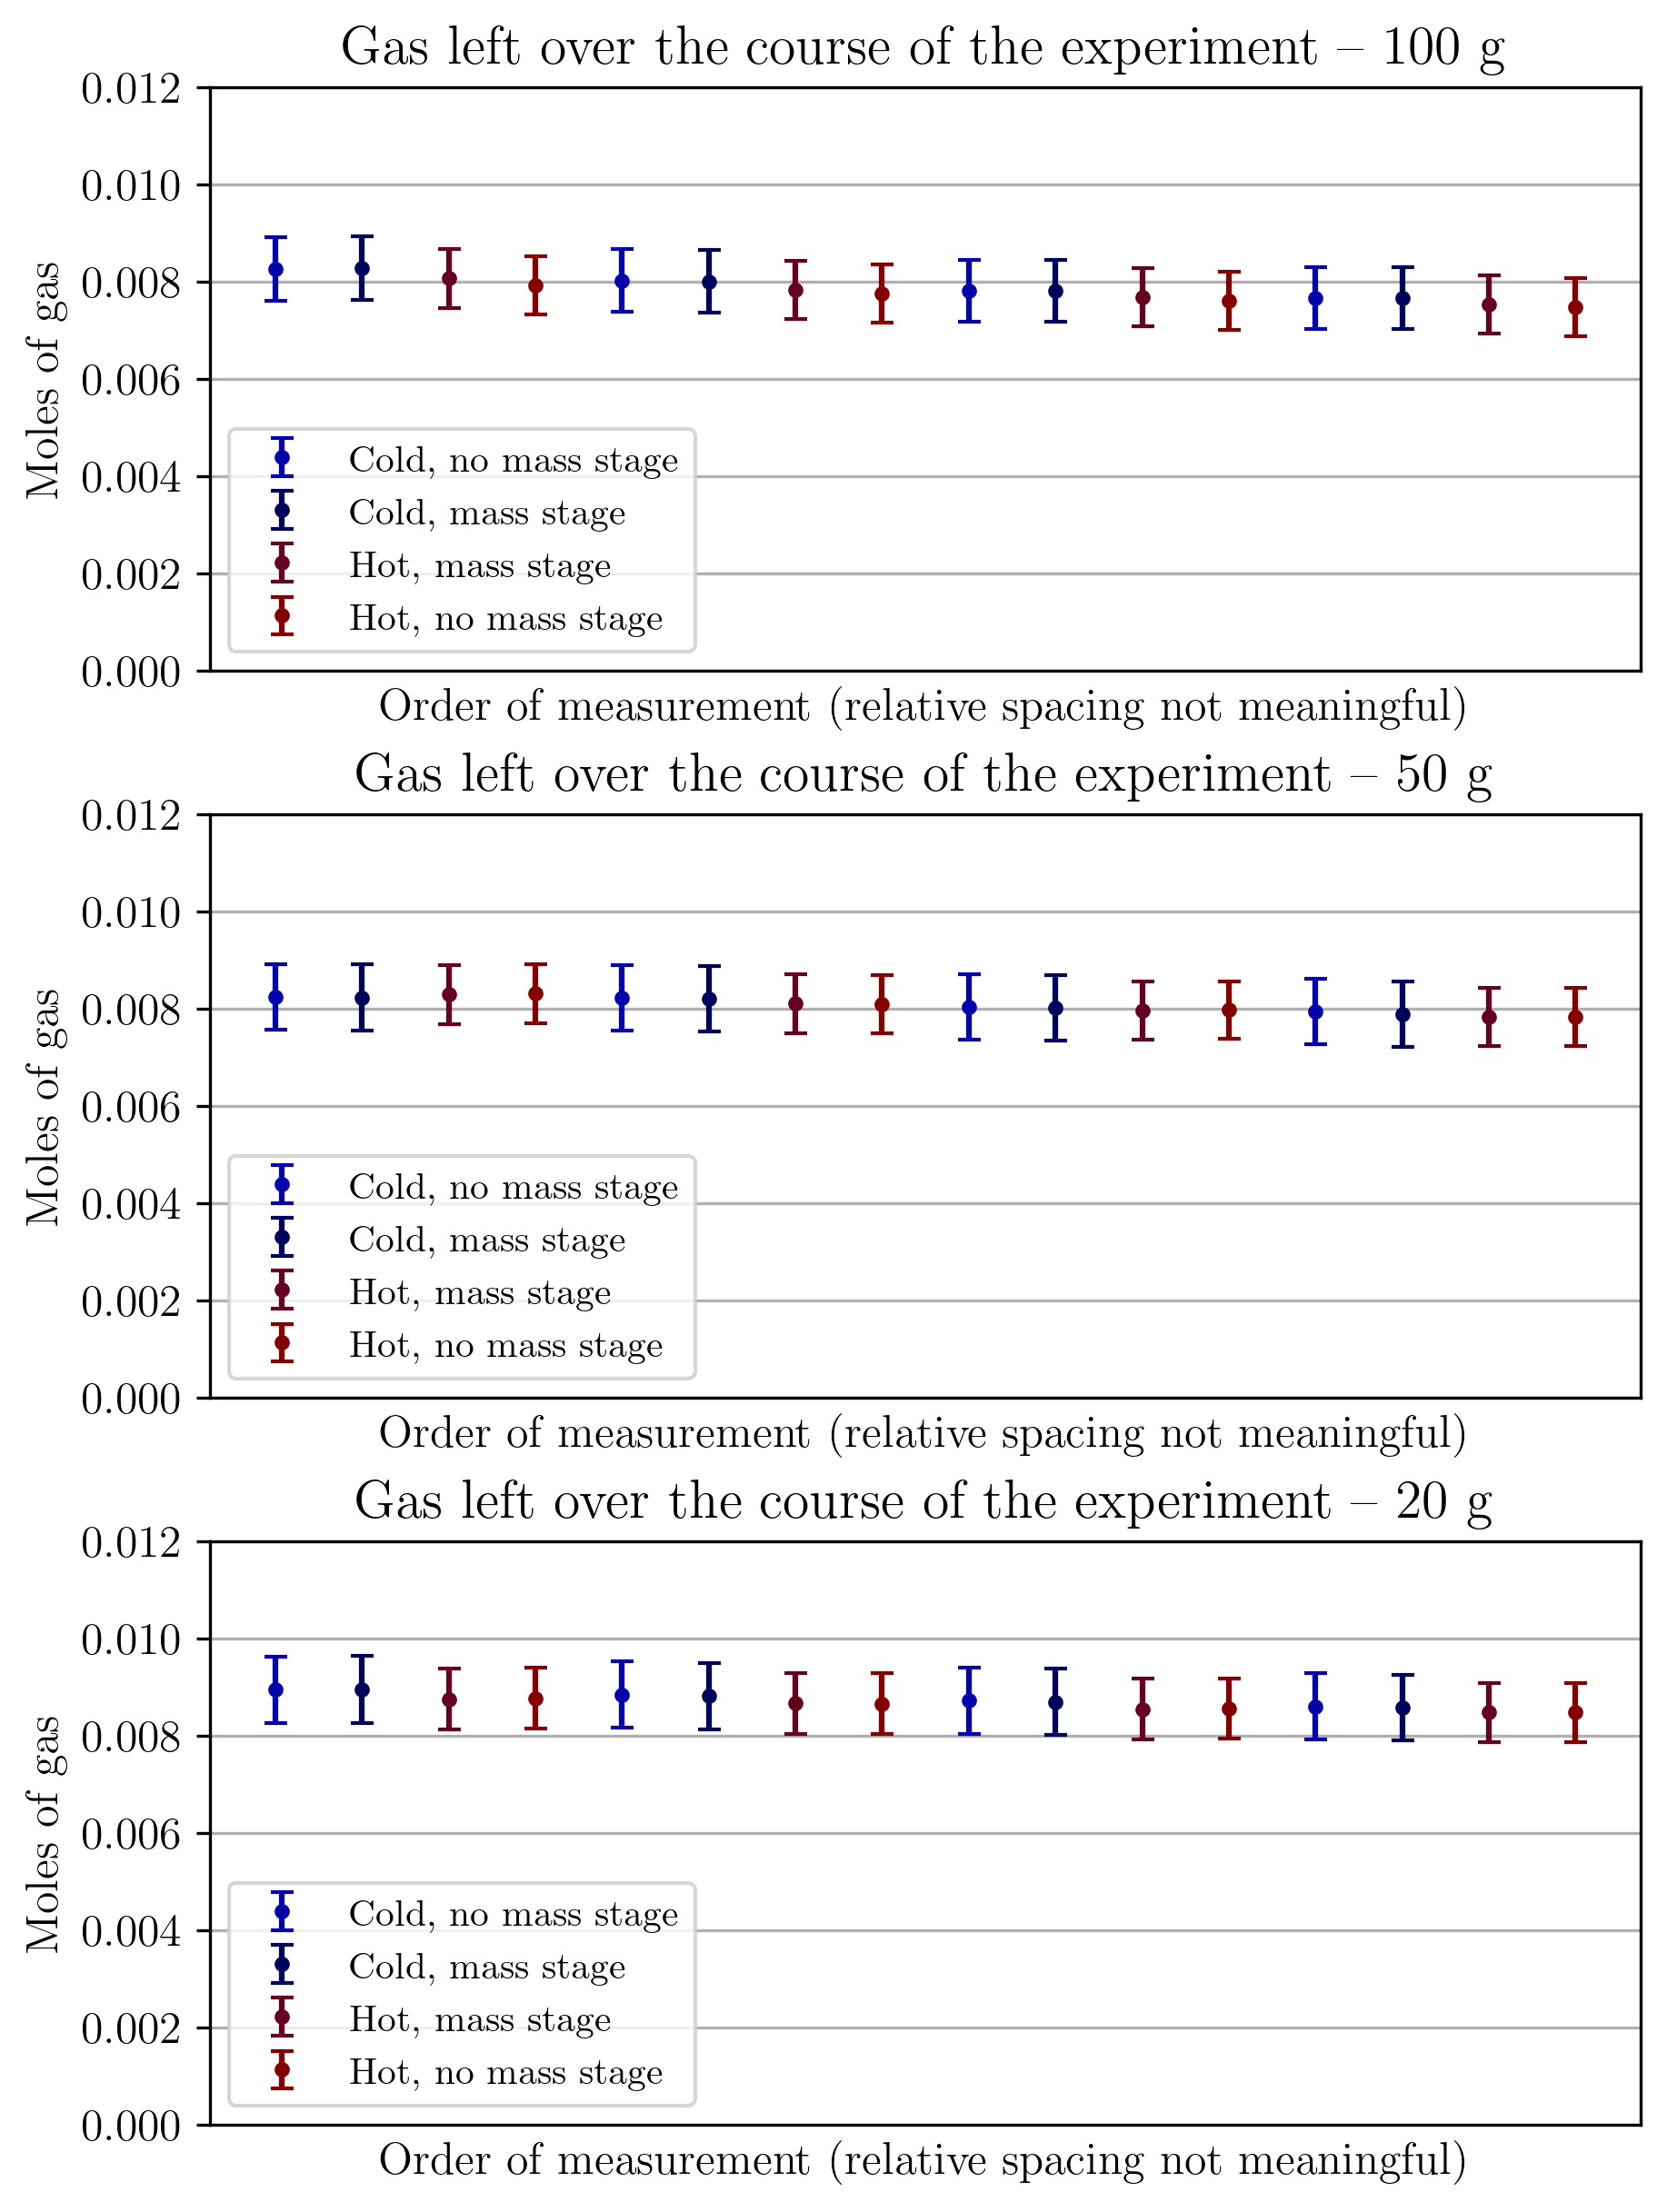

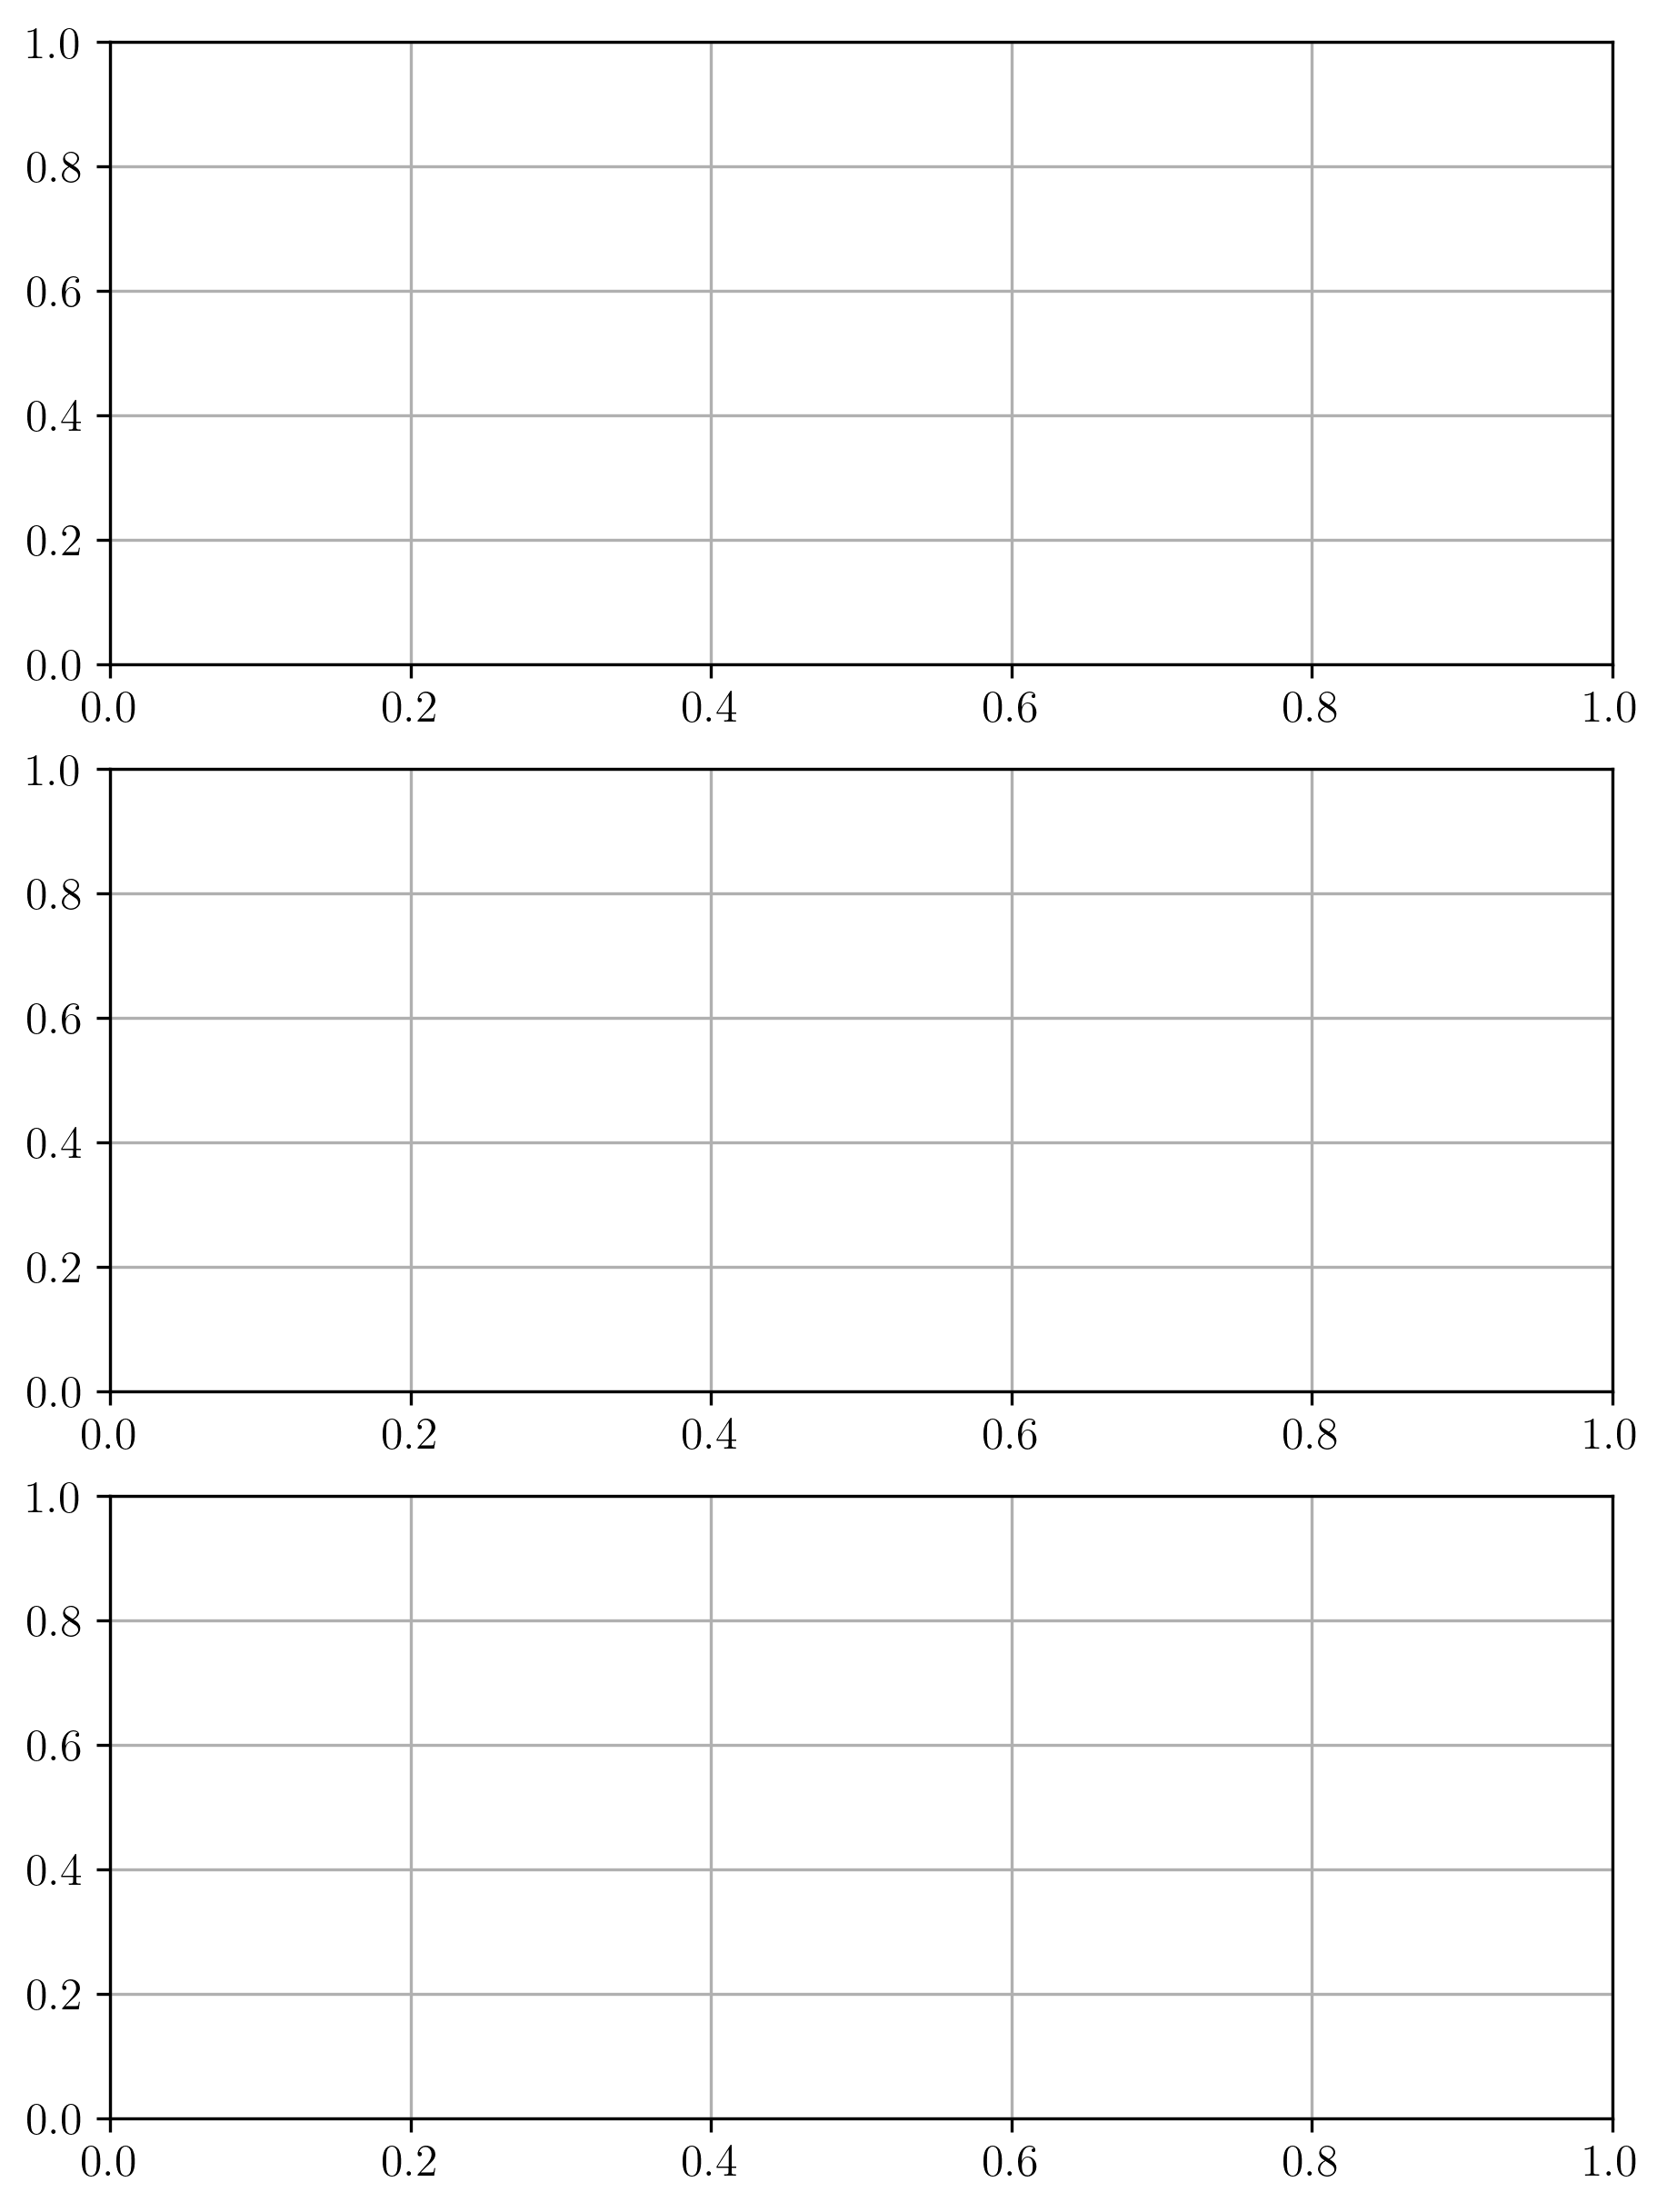

In [620]:
# CYCLE:
# 1, putting mass on cold - isothermal compression at temperature T_cold
# 2, heating up piston to hot - isobaric expansion T_cold --> T_hot at high pressure
# 3, taking mass off hot - isothermal expansion at temperature T_hot
# 4, cooling piston back to cold - isobaric compression T_hot --> T_cold_after 


N_fig, N_axs = plt.subplots(3, 1, figsize=(6,8), layout='constrained')

work_fig, work_axs = plt.subplots(3, 1, figsize=(6,8), layout='constrained')


for i in range(3):
    
    cold_temps_before = cold_temps[i][:-1]
    cold_temps_before_err = cold_temps_err[i][:-1]

    cold_temps_after = cold_temps[i][1:]
    cold_temps_after_err = cold_temps_err[i][1:]

    cold_volumes_before = cold_volumes[i][:-1]
    cold_volumes_before_err = cold_volumes_err[i][:-1]

    cold_volumes_after = cold_volumes[i][1:]
    cold_volumes_after_err = cold_volumes_err[i][1:]

    N1 = low_pressure * cold_volumes_before / (k_B * cold_temps_before)
    N2 = high_pressures[i] * cold_volumes_mass[i] / (k_B * cold_temps_before)
    N3 = high_pressures[i] * hot_volumes_mass[i] / (k_B * hot_temps[i])
    N4 = low_pressure * hot_volumes[i] / (k_B * hot_temps[i])
    N5 = low_pressure * cold_volumes_after / (k_B * cold_temps_after)

    N1_err = N1 * np.sqrt((low_pressure_err / low_pressure)**2 + (cold_volumes_before_err / cold_volumes_before)**2 + (cold_temps_before_err / cold_temps_before)**2)
    N2_err = N2 * np.sqrt((high_pressures_err[i] / high_pressures[i])**2 + (cold_volumes_mass_err[i] / cold_volumes_mass[i])**2 + (cold_temps_before_err / cold_temps_before)**2)
    N3_err = N3 * np.sqrt((high_pressures_err[i] / high_pressures[i])**2 + (hot_volumes_mass_err[i] / hot_volumes_mass[i])**2 + (hot_temps_err[i] / hot_temps[i])**2)
    N4_err = N4 * np.sqrt((low_pressure_err / low_pressure)**2 + (hot_volumes_err[i] / hot_volumes[i])**2 + (hot_temps_err[i] / hot_temps[i])**2)
    N5_err = N5 * np.sqrt((low_pressure_err / low_pressure)**2 + (cold_volumes_after_err / cold_volumes_after)**2 + (cold_temps_after_err / cold_temps_after)**2)

    # print(N1)
    # print(N2)
    # print(N3)
    # print(N4)
    # print(N5)

    W1 = N1 * k_B * cold_temps_before * np.log(cold_volumes_mass[i] / cold_volumes_before)

    W1_alt = 0.5 * (N1 + N2) * k_B * cold_temps_before * np.log(low_pressure / high_pressures[i])

    W1_approx = 0.5 * (high_pressures[i] + low_pressure) * (cold_volumes_mass[i] - cold_volumes_before)

    W2 = N2 * k_B * (hot_temps[i] - cold_temps_before)
    W2_alt = k_B * (N3*hot_temps[i] - N2*cold_temps_before)


    W3 = N3 * k_B * hot_temps[i] * np.log(hot_volumes[i] / hot_volumes_mass[i])
    W3_alt = 0.5 * (N3 + N4) * k_B * hot_temps[i] * np.log(high_pressures[i] / low_pressure)

    W3_approx = 0.5 * (high_pressures[i] + low_pressure) * (hot_volumes[i] - hot_volumes_mass[i])

    W4 = N4 * k_B * (cold_temps_after - hot_temps[i])
    W4_alt = k_B * (N5*cold_temps_after - N4*hot_temps[i])

    W_total = W1 + W2_alt + W3 + W4
    W_total_alt = W1_alt + W2_alt + W3_alt + W4_alt


    W_simple = N1 * k_B * (hot_temps[i] - cold_temps_before) * np.log(high_pressures[i] / low_pressure)

    W_simple_err_N = k_B * N1_err * (hot_temps[i] - cold_temps_before) * np.log(high_pressures[i] / low_pressure)
    W_simple_err_temps = k_B * N1 * np.log(high_pressures[i] / low_pressure) * np.sqrt(hot_temps_err[i]**2 + cold_temps_before_err**2)
    W_simple_err_P = k_B * N1 * (hot_temps[i] - cold_temps_before) * np.sqrt((high_pressures_err[i] / high_pressures[i])**2 + (low_pressure_err / low_pressure)**2)
    
    W_simple_err = np.sqrt(W_simple_err_N**2 + W_simple_err_temps**2 + 0*W_simple_err_P**2)

    # print(W_simple_err_P)
    # print(W_simple)
    # print("------------")
    # print(W1)
    # print(W2_alt)
    # print(W3)
    # print(W4)

    #print("Total work: ", W_total)
    # print("Simple work: ", W_simple)

    work_on_mass = masses[i] * g * (hot_heights_mass[i] - cold_heights_mass[i])
    work_on_mass_err = np.sqrt((masses_err[i] * g * (hot_heights_mass[i] - cold_heights_mass[i]))**2 + (masses[i]*g * hot_heights_mass_err[i])**2 + (masses[i]*g * cold_heights_mass_err[i])**2)

    # print("Work on mass: ", work_on_mass)

    # print("Simple Efficiency: ", work_on_mass / W_simple)

    time_ordered_N = np.vstack((N1, N2, N3, N4)).T.ravel() / N_A
    time_ordered_N_err = np.vstack((N1_err, N2_err, N3_err, N4_err)).T.ravel() / N_A
    #print(time_ordered_N_err / time_ordered_N)


    efficiency = work_on_mass / W_simple
    efficiency_err = efficiency * np.sqrt((work_on_mass_err / work_on_mass)**2 + (W_simple_err / W_simple)**2)

    print("---------------")
    print(f"{masses[i]*1000:0.0f} g Mass:")
    print("Work on mass: ", work_on_mass*1e3)
    print("Work on mass err: ", work_on_mass_err*1e3)
    print("Work by gas: ", W_simple * 1e3)
    print("Work by gas err: ", W_simple_err * 1e3)
    print("Efficiency: ", efficiency)
    print("Efficiency err: ", efficiency_err)
    print("Average efficiency: ", np.mean(efficiency), "Mean Error: ", np.sqrt(np.sum(efficiency_err**2)) / len(efficiency_err))
    
    

    

    N_axs[i].errorbar(1 + np.array([0,4,8,12]), N1 / N_A, N1_err / N_A, fmt = 'o', markersize = 3, capsize = 3, color = 'xkcd:royal blue', zorder=10, label = "Cold, no mass stage")
    N_axs[i].errorbar(2 + np.array([0,4,8,12]), N2 / N_A, N2_err / N_A, fmt = 'o', markersize = 3, capsize = 3, color = 'xkcd:dark blue', zorder=10, label = "Cold, mass stage")
    N_axs[i].errorbar(3 + np.array([0,4,8,12]), N3 / N_A, N3_err / N_A, fmt = 'o', markersize = 3, capsize = 3, color = 'xkcd:maroon', zorder=10, label = "Hot, mass stage")
    N_axs[i].errorbar(4 + np.array([0,4,8,12]), N4 / N_A, N4_err / N_A, fmt = 'o', markersize = 3, capsize = 3, color = 'xkcd:dark red', zorder=10, label = "Hot, no mass stage")

    N_axs[i].set_ylim(0, 0.012)
    N_axs[i].set_ylabel("Moles of gas")
    N_axs[i].set_xlabel("Order of measurement (relative spacing not meaningful)")
    N_axs[i].set_title(f"Gas left over the course of the experiment -- {masses[i]*1000:0.0f} g")
    N_axs[i].tick_params(axis='x', labelbottom=False)
    N_axs[i].set_xticks([])
    N_axs[i].legend(fontsize=10)

    #N_fig.savefig("plots/N_vs_time.png", dpi=400)

In [621]:
# PV_fig, PV_ax = plt.subplots(1, figsize=(6, 4), layout="constrained")


# chronological_pressures = np.array([low_pressure, high_pressure, high_pressure, low_pressure] * len(cold_volumes))

# #Interleaves in order of the 4-tuple passed to vstack
# chronological_volumes = np.vstack((cold_volumes, cold_volumes_mass, hot_volumes_mass, hot_volumes)).flatten(order="F")

# #PV_ax.plot(chronological_volumes, chronological_pressures, '-o')

# #PV_ax.plot([cold_volumes[0], cold_volumes_mass[0], hot_volumes_mass[0], hot_volumes[0]], [low_pressure, high_pressure, high_pressure, low_pressure], '-o')